# Exercise7.01: Comparing IQ scores using a box plot

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 01

Data: `iq_scores.csv`. 

## Exercise7.01 — 01. Import modules and read the IQ data

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
mydata = pd.read_csv(DATA_DIR / 'iq_scores.csv')
print('Input shape:', mydata.shape)
display(mydata.head())

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Input shape: (100, 4)


,group_a,group_b,group_c,group_d
0,118,126,108,93
1,103,89,89,99
2,125,90,114,91
3,107,101,116,110
4,111,102,126,80


## Exercise7.01 — 02. Convert all four columns to lists

In [2]:
group_a = mydata[mydata.columns[0]].tolist()
group_b = mydata[mydata.columns[1]].tolist()
group_c = mydata[mydata.columns[2]].tolist()
group_d = mydata[mydata.columns[3]].tolist()
print('Group A:', group_a)
print('Group B:', group_b)
print('Group C:', group_c)
print('Group D:', group_d)
print('Types:', [type(g).__name__ for g in [group_a, group_b, group_c, group_d]])

Group A: [118, 103, 125, 107, 111, 96, 104, 97, 96, 114, 96, 75, 114, 107, 87, 117, 117, 114, 117, 112, 107, 133, 94, 91, 118, 110, 117, 86, 143, 83, 106, 86, 98, 126, 109, 91, 112, 120, 108, 111, 107, 98, 89, 113, 117, 81, 113, 112, 84, 115, 96, 93, 128, 115, 138, 121, 87, 112, 110, 79, 100, 84, 115, 93, 108, 130, 107, 106, 106, 101, 117, 93, 94, 103, 112, 98, 103, 70, 139, 94, 110, 105, 122, 94, 94, 105, 129, 110, 112, 97, 109, 121, 106, 118, 131, 88, 122, 125, 93, 78]
Group B: [126, 89, 90, 101, 102, 74, 93, 101, 66, 120, 108, 97, 98, 105, 119, 92, 113, 81, 104, 108, 83, 102, 105, 111, 102, 107, 103, 89, 89, 110, 71, 110, 120, 85, 111, 83, 122, 120, 102, 84, 118, 100, 100, 114, 81, 109, 69, 97, 95, 106, 116, 109, 114, 98, 90, 92, 98, 91, 81, 85, 86, 102, 93, 112, 76, 89, 110, 75, 110, 90, 96, 94, 107, 108, 95, 96, 96, 114, 93, 95, 117, 141, 115, 95, 86, 100, 121, 103, 66, 99, 96, 111, 110, 105, 110, 91, 112, 102, 112, 75]
Group C: [108, 89, 114, 116, 126, 104, 113, 96, 69, 121, 109,

## Exercise7.01 — 03. Construct and check the long-form DataFrame

In [3]:
data = pd.DataFrame({
    'Groups': ['Group A'] * len(group_a) + ['Group B'] * len(group_b)
              + ['Group C'] * len(group_c) + ['Group D'] * len(group_d),
    'IQ score': group_a + group_b + group_c + group_d
})
print(data.columns)
print('Long-form shape:', data.shape)
display(data.groupby('Groups')['IQ score'].agg(['count', 'median', 'min', 'max']))

Index(['Groups', 'IQ score'], dtype='str')
Long-form shape: (400, 2)


,count,median,min,max
Groups,,,,
Group A,100,107.0,70,143
Group B,100,100.5,66,141
Group C,100,105.0,69,137
Group D,100,98.0,54,131


## Exercise7.01 — 04. Draw the required box plot

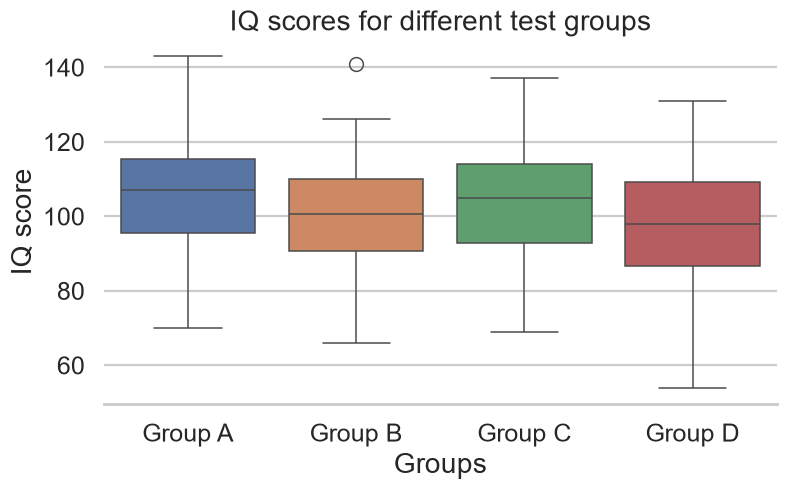

In [4]:
sns.set_theme(style='whitegrid', context='talk')
plt.figure(figsize=(7.5, 4.8), dpi=110)
sns.boxplot(data=data, x='Groups', y='IQ score', hue='Groups',
            palette='deep', legend=False)
sns.despine(left=True, right=True, top=True)
plt.title('IQ scores for different test groups')
plt.tight_layout()
plt.show()

Group A has the highest sample median and Group D the lowest. The groups overlap substantially. The isolated high score in Group B is visible as an outlier; the diagram does not establish population differences.